# Avance 6: Segmentación Espacio-Temporal con U-TAE (PASTIS Dataset)

**Dataset:** PASTIS (series temporales Sentinel-2)
**Marco de Trabajo:** Metodología CRISP-ML(Q) — Fase de Modeling (continuación) y Evaluation
**Equipo:** 13

---

## Tabla de Contenidos Metodológica

### 1. Configuración del Entorno y Acceso a los Datos
- Detección automática del entorno (Kaggle, Colab o equipo local) y de la ruta del dataset, sin descargas.
- Verificación de la GPU, la memoria disponible y la precisión numérica.
- Metadatos, particiones oficiales (folds 1–3 / 4 / 5) y fechas de adquisición.

### 2. Preparación de los Datos
- Estadísticas de normalización por banda y pesos de clase calculados solo con entrenamiento.
- Dataset de parches completos con submuestreo temporal y aumentación geométrica.

### 3. Modelo U-TAE
- Implementación de U-TAE (Garnot & Landrieu, 2021), integrada en el notebook a partir del repositorio oficial.

### 4. Función de Pérdida y Métricas
- Cross-entropy ponderada + Dice, ignorando Void; mIoU, Macro F1 y Accuracy con las 19 clases.

### 5. Ajuste de Memoria y Entrenamiento
- Selección automática de `BATCH_SIZE` y `T_TRAIN` según la VRAM.
- Entrenamiento con checkpoints, reanudación y límite de tiempo por sesión.

### 6. Evaluación en Validación y Selección Final
- Mejor checkpoint por mIoU de validación; decisión sobre aumentación en inferencia (TTA) con validación.

### 7. Evaluación con Datos No Vistos (fold 5)
- Métricas sobre parches completos, resultados por clase y matriz de confusión.
- Comparación justa con el Avance 5 sobre **los mismos 9,000 píxeles** de prueba.

### 8. Conclusiones Metodológicas CRISP-ML(Q)

### Declaración sobre el uso de herramientas de inteligencia artificial

## 1. Configuración del Entorno y Acceso a los Datos

En el Avance 5 los clasificadores trabajaban con **52 estadísticas temporales por píxel**. Ese enfoque descarta el orden de la serie y el contexto espacial de las parcelas, y el mejor modelo (Voting heterogéneo) se quedó en Macro F1 = 0.345 en prueba, con varias clases minoritarias prácticamente en cero. En este avance se entrena **U-TAE**, que recibe la serie completa `(T, 10, 128, 128)` de cada parche y produce una etiqueta por píxel.

Se mantienen las mismas decisiones de evaluación de los avances anteriores:
- **Particiones oficiales:** folds 1–3 entrenamiento, fold 4 validación y fold 5 prueba. El fold 5 solo se usa al final, con el modelo ya elegido.
- **Clases:** Fondo (0) y 18 cultivos (1–18). **Void (19)** se ignora en la pérdida y en las métricas.
- **Macro promedios** con las 19 clases; una clase sin píxeles reales ni predichos cuenta 0.

**Acceso a datos sin descarga.** En Kaggle basta con añadir el dataset `a01634782/pastis` como *Input* del notebook: se lee directamente desde `/kaggle/input`. En un equipo local se indica la carpeta `PASTIS` mediante la variable `RUTA_LOCAL_PASTIS` o la variable de entorno `PASTIS_ROOT`. El notebook **nunca** descarga el dataset por sí mismo.

In [6]:
# ==============================================================================
# 1.1 CONFIGURACIÓN DEL ENTORNO, LIBRERÍAS Y PARÁMETROS
# ==============================================================================
import os
import sys
import json
import glob
import time
import math
import copy
import random
import shutil
import platform
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# ------------------------------------------------------------------------------
# PARÁMETROS DEL EXPERIMENTO
# ------------------------------------------------------------------------------
# True -> prueba de humo (pocos parches y 2 épocas) para verificar que todo corre.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"

# Ruta de la carpeta PASTIS en un equipo local (la que contiene metadata.geojson,
# DATA_S2/ y ANNOTATIONS/). En Kaggle no hace falta: se detecta sola.
RUTA_LOCAL_PASTIS = r"C:\Users\lalo4\Downloads\PASTIS\PASTIS"        # p. ej. r"D:\datasets\PASTIS"

EPOCHS          = 100             # como en el artículo original de U-TAE
PATIENCE        = 30              # épocas sin mejorar mIoU de validación antes de parar
LR              = 1e-3
WEIGHT_DECAY    = 1e-4
WARMUP_EPOCHS   = 2               # calentamiento lineal del learning rate
EFFECTIVE_BATCH = 4               # lote efectivo; si la VRAM obliga a un lote menor se acumulan gradientes
T_TRAIN_OBJETIVO = 32             # fechas por parche en entrenamiento (submuestreo aleatorio)
BATCH_SIZE      = None            # None -> se elige automáticamente según la VRAM (sección 5.1)
T_TRAIN         = None            # None -> se elige automáticamente según la VRAM (sección 5.1)
DICE_WEIGHT     = 1.0             # peso del término Dice
PESO_MIN, PESO_MAX = 0.2, 8.0     # cotas de los pesos de clase
N_PARCHES_NORM  = 150             # parches de entrenamiento para estimar media/desviación
GRAD_CLIP       = 1.0
EVALUAR_PRUEBA  = True            # el fold 5 se evalúa una sola vez, al final, con el modelo elegido
PROBAR_TTA      = True            # decidir con validación si se usa TTA (giros) en la inferencia
SEED            = 42

NUM_CLASSES = 19                  # 0 = Fondo, 1..18 = cultivos
VOID_LABEL  = 19
REFERENCE_DATE = datetime(2018, 9, 1)

if MODO_RAPIDO:
    EPOCHS, PATIENCE, N_PARCHES_NORM = 2, 5, 10
    MAX_PATCHES = {"train": 24, "val": 8, "test": 8}
else:
    MAX_PATCHES = {"train": None, "val": None, "test": None}   # None = todos los parches del fold

NOMBRES_CLASES = {
    0: "Fondo", 1: "Pradera", 2: "Trigo blando de invierno", 3: "Maíz",
    4: "Cebada de invierno", 5: "Colza de invierno", 6: "Cebada de primavera",
    7: "Girasol", 8: "Vid", 9: "Remolacha", 10: "Triticale de invierno",
    11: "Trigo duro de invierno", 12: "Frutas, hortalizas y flores", 13: "Papa",
    14: "Forraje leguminoso", 15: "Soya", 16: "Huerto", 17: "Cereal mixto",
    18: "Sorgo",
}

# ------------------------------------------------------------------------------
# ENTORNO DE EJECUCIÓN Y CARPETA DE TRABAJO
# ------------------------------------------------------------------------------
EN_KAGGLE = os.path.isdir("/kaggle/input")
EN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content/sample_data")
ENTORNO = "Kaggle" if EN_KAGGLE else ("Colab" if EN_COLAB else "Local")

if EN_KAGGLE:
    WORK_DIR = Path("/kaggle/working")
    MAX_HORAS_SESION = 11.0       # Kaggle corta las sesiones con GPU a las 12 h
elif EN_COLAB and os.path.isdir("/content/drive/MyDrive"):
    WORK_DIR = Path("/content/drive/MyDrive/pastis_utae")
    MAX_HORAS_SESION = None
else:
    WORK_DIR = Path(os.environ.get("UTAE_WORK_DIR", "salidas_utae"))
    MAX_HORAS_SESION = None
# La prueba rápida usa su propia carpeta para que nunca se "reanude" su checkpoint en la corrida completa.
CKPT_DIR = WORK_DIR / ("utae_ckpt_rapido" if MODO_RAPIDO else "utae_ckpt")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# En Windows los procesos de DataLoader no pueden importar clases definidas en el
# notebook, así que la carga se hace en el proceso principal.
NUM_WORKERS = 0 if os.name == "nt" else min(4, os.cpu_count() or 1)

def fijar_semillas(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
fijar_semillas(SEED)

print("=== VERIFICACIÓN DEL ENTORNO ===")
print("Entorno:", ENTORNO, "| Python", platform.python_version(), "| torch", torch.__version__,
      "| numpy", np.__version__)
print("Modo rápido:", MODO_RAPIDO, "| Épocas:", EPOCHS, "| Workers:", NUM_WORKERS)
print("Carpeta de trabajo:", WORK_DIR.resolve())
print("Checkpoints en:", CKPT_DIR.resolve())

=== VERIFICACIÓN DEL ENTORNO ===
Entorno: Local | Python 3.12.16 | torch 2.5.1+cu121 | numpy 2.5.4
Modo rápido: False | Épocas: 100 | Workers: 0
Carpeta de trabajo: C:\Users\lalo4\Downloads\Avances\salidas_utae
Checkpoints en: C:\Users\lalo4\Downloads\Avances\salidas_utae\utae_ckpt


In [7]:
# ==============================================================================
# 1.2 GPU, MEMORIA Y PRECISIÓN NUMÉRICA
# ==============================================================================
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VRAM_GB = 0.0
AMP_DTYPE = None                  # None = sin precisión mixta

if DEVICE.type == "cuda":
    prop = torch.cuda.get_device_properties(0)
    VRAM_GB = prop.total_memory / 1024 ** 3
    cc = torch.cuda.get_device_capability(0)
    print(f"GPU: {prop.name} | VRAM: {VRAM_GB:.1f} GB | compute capability {cc[0]}.{cc[1]}")
    # Comprobación de que la versión de PyTorch tiene kernels para esta GPU
    # (algunas versiones recientes ya no incluyen soporte para la P100, cc 6.0).
    try:
        _ = (torch.randn(64, 64, device=DEVICE) @ torch.randn(64, 64, device=DEVICE)).sum().item()
    except RuntimeError as exc:
        raise RuntimeError("Esta GPU no es compatible con la versión instalada de PyTorch. "
                           "En Kaggle elige 'GPU T4 x2' en lugar de P100.") from exc
    if torch.cuda.is_bf16_supported() and cc[0] >= 8:
        AMP_DTYPE = torch.bfloat16    # A100, RTX 30xx/40xx: bf16 no necesita escalado de gradiente
    else:
        AMP_DTYPE = torch.float16     # T4 / P100: fp16 con GradScaler
    torch.backends.cudnn.benchmark = True
else:
    print("AVISO: no hay GPU. El entrenamiento completo sería extremadamente lento.")

USE_AMP = AMP_DTYPE is not None
print("Precisión mixta:", AMP_DTYPE if USE_AMP else "desactivada")

def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE or torch.float32, enabled=USE_AMP)

GPU: NVIDIA GeForce RTX 4050 Laptop GPU | VRAM: 6.0 GB | compute capability 8.9
Precisión mixta: torch.bfloat16


In [8]:
# ==============================================================================
# 1.3 LOCALIZACIÓN DEL DATASET (SIN DESCARGA)
# ==============================================================================
def es_raiz_pastis(p):
    p = Path(p)
    return (p / "metadata.geojson").is_file() and (p / "DATA_S2").is_dir() and (p / "ANNOTATIONS").is_dir()

def buscar_raiz_pastis():
    candidatos = [os.environ.get("PASTIS_ROOT"), RUTA_LOCAL_PASTIS,
                  "/kaggle/input/pastis/PASTIS", "/content/PASTIS",
                  "/content/drive/MyDrive/PASTIS", "PASTIS", "../PASTIS"]
    for c in candidatos:
        if c and es_raiz_pastis(c):
            return Path(c)
    # Kaggle puede montar el dataset con otra estructura de carpetas: se busca el archivo de metadatos.
    if EN_KAGGLE:
        for meta in sorted(glob.glob("/kaggle/input/**/metadata.geojson", recursive=True)):
            if es_raiz_pastis(Path(meta).parent):
                return Path(meta).parent
    raise FileNotFoundError(
        "No se encontró la carpeta PASTIS (con metadata.geojson, DATA_S2/ y ANNOTATIONS/).\n"
        "- Kaggle: 'Add Input' -> dataset a01634782/pastis.\n"
        "- Local: asigna RUTA_LOCAL_PASTIS en la celda 1.1 o define la variable de entorno PASTIS_ROOT.")

PASTIS_ROOT = buscar_raiz_pastis()

def ruta_s2(pid):
    return PASTIS_ROOT / "DATA_S2" / f"S2_{pid}.npy"

def ruta_target(pid):
    return PASTIS_ROOT / "ANNOTATIONS" / f"TARGET_{pid}.npy"

print("=== DATASET PASTIS ===")
print("Raíz:", PASTIS_ROOT)
print("Archivos S2:", len(list((PASTIS_ROOT / "DATA_S2").glob("S2_*.npy"))),
      "| Archivos TARGET:", len(list((PASTIS_ROOT / "ANNOTATIONS").glob("TARGET_*.npy"))))

=== DATASET PASTIS ===
Raíz: C:\Users\lalo4\Downloads\PASTIS\PASTIS
Archivos S2: 2468 | Archivos TARGET: 2433


In [9]:
# ==============================================================================
# 1.4 METADATOS, PARTICIONES OFICIALES Y FECHAS
# ==============================================================================
with open(PASTIS_ROOT / "metadata.geojson", "r") as f:
    geojson = json.load(f)
metadata = pd.DataFrame([ft["properties"] for ft in geojson["features"]])
metadata["ID_PATCH"] = metadata["ID_PATCH"].astype(int)

def fechas_a_dias(valor):
    # dates-S2 es un diccionario {"0": 20180924, "1": 20181004, ...}; se ordena por índice.
    if isinstance(valor, str):
        valor = json.loads(valor)
    fechas = [str(valor[k]) for k in sorted(valor, key=lambda x: int(x))]
    return np.array([(datetime.strptime(d, "%Y%m%d") - REFERENCE_DATE).days for d in fechas], dtype=np.int64)

DATES = {int(r["ID_PATCH"]): fechas_a_dias(r["dates-S2"]) for _, r in metadata.iterrows()}

def tomar(df, n):
    ids = sorted(df["ID_PATCH"].astype(int).tolist())
    if n is not None and n < len(ids):
        ids = sorted(np.random.default_rng(SEED).choice(ids, n, replace=False).tolist())
    return ids

FOLDS_COMPLETOS = {"train": metadata[metadata["Fold"].isin([1, 2, 3])],
                   "val": metadata[metadata["Fold"] == 4],
                   "test": metadata[metadata["Fold"] == 5]}
IDS = {k: tomar(v, MAX_PATCHES[k]) for k, v in FOLDS_COMPLETOS.items()}
assert set(IDS["train"]).isdisjoint(IDS["val"])
assert set(IDS["train"]).isdisjoint(IDS["test"])
assert set(IDS["val"]).isdisjoint(IDS["test"])

# Comprobación de consistencia: cada archivo existe y su número de fechas coincide con los metadatos.
# (Solo se lee la cabecera de cada .npy mediante mmap.)
problemas = []
for pid in tqdm(IDS["train"] + IDS["val"] + IDS["test"], desc="Verificando archivos"):
    if not ruta_s2(pid).is_file() or not ruta_target(pid).is_file():
        problemas.append((pid, "archivo faltante")); continue
    forma = np.load(ruta_s2(pid), mmap_mode="r").shape
    if len(forma) != 4 or forma[1] != 10 or forma[0] != len(DATES[pid]):
        problemas.append((pid, f"forma {forma} vs {len(DATES[pid])} fechas"))
if problemas:
    raise ValueError(f"{len(problemas)} parches con problemas, p. ej.: {problemas[:5]}")

print("Distribución de folds:", metadata["Fold"].value_counts().sort_index().to_dict())
print("Parches usados:", {k: len(v) for k, v in IDS.items()})
T_all = np.array([len(DATES[i]) for i in IDS["train"]])
print(f"Fechas por parche (train): mín={T_all.min()} · mediana={int(np.median(T_all))} · máx={T_all.max()}")
print("Verificación de separación de folds y de archivos: CORRECTA")

Verificando archivos:   0%|          | 0/2433 [00:00<?, ?it/s]

Distribución de folds: {1: 487, 2: 494, 3: 474, 4: 482, 5: 496}
Parches usados: {'train': 1455, 'val': 482, 'test': 496}
Fechas por parche (train): mín=38 · mediana=46 · máx=61
Verificación de separación de folds y de archivos: CORRECTA


## 2. Preparación de los Datos

**Normalización.** Media y desviación estándar por banda, estimadas con una muestra reproducible de parches de **entrenamiento**. Se guardan en `normalizacion.json`, de modo que una reanudación usa exactamente los mismos valores.

**Pesos de clase.** Se cuentan los píxeles de todas las anotaciones de entrenamiento (archivos pequeños). Peso = `1/√frecuencia`, normalizado a media 1 y acotado a `[0.2, 8]`. El inverso puro de la frecuencia (desbalance 342:1 observado en el Avance 5) tiende a desestabilizar el entrenamiento.

In [10]:
# ==============================================================================
# 2.1 ESTADÍSTICAS DE NORMALIZACIÓN POR BANDA (SOLO ENTRENAMIENTO)
# ==============================================================================
RUTA_NORM = WORK_DIR / "normalizacion.json"
firma_norm = f"{SEED}|{N_PARCHES_NORM}|{len(IDS['train'])}|{IDS['train'][:5]}"

if RUTA_NORM.is_file() and json.loads(RUTA_NORM.read_text()).get("firma") == firma_norm:
    _n = json.loads(RUTA_NORM.read_text())
    MEAN, STD = np.array(_n["mean"], np.float32), np.array(_n["std"], np.float32)
    print("Estadísticas recuperadas de", RUTA_NORM)
else:
    muestra = np.random.default_rng(SEED).choice(IDS["train"], min(N_PARCHES_NORM, len(IDS["train"])), replace=False)
    suma = np.zeros(10, np.float64); suma2 = np.zeros(10, np.float64); n = 0
    for pid in tqdm(muestra, desc="Estadísticas por banda"):
        x = np.load(ruta_s2(int(pid))).astype(np.float64)              # (T, 10, H, W)
        suma += x.sum(axis=(0, 2, 3)); suma2 += (x ** 2).sum(axis=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    MEAN = (suma / n).astype(np.float32)
    STD = np.sqrt(np.maximum(suma2 / n - (suma / n) ** 2, 1e-6)).astype(np.float32)
    RUTA_NORM.write_text(json.dumps({"firma": firma_norm, "mean": MEAN.tolist(), "std": STD.tolist()}))

bandas_s2 = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
display(pd.DataFrame({"Banda": bandas_s2, "Media": MEAN.round(1), "Desv. estándar": STD.round(1)}).T)

Estadísticas por banda:   0%|          | 0/150 [00:00<?, ?it/s]

,0,1,2,3,4,5,6,7,8,9
Banda,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12
Media,1161.400024,1378.300049,1446.699951,1777.300049,2697.0,3029.699951,3168.5,3283.899902,2446.199951,1661.0
Desv. estándar,2043.0,1983.699951,2057.399902,1969.599976,1875.199951,1892.099976,1905.5,1894.699951,1563.599976,1395.900024


Frecuencias de clase:   0%|          | 0/1455 [00:00<?, ?it/s]

,Clase,Nombre,Píxeles train,% train,Peso
0,0,Fondo,9526859,44.102,0.200
1,1,Pradera,4335282,20.069,0.256
2,2,Trigo blando de invierno,1592649,7.373,0.422
3,3,Maíz,2142796,9.920,0.364
4,4,Cebada de invierno,475792,2.203,0.773
5,5,Colza de invierno,418245,1.936,0.824
6,6,Cebada de primavera,145623,0.674,1.397
7,7,Girasol,222719,1.031,1.129
8,8,Vid,701765,3.249,0.636
9,9,Remolacha,186211,0.862,1.235


Píxeles Void (ignorados): 2,236,875 (9.4% del total)
Desbalance entre clases presentes (máx/mín): 138:1
Clases sin píxeles en entrenamiento: []


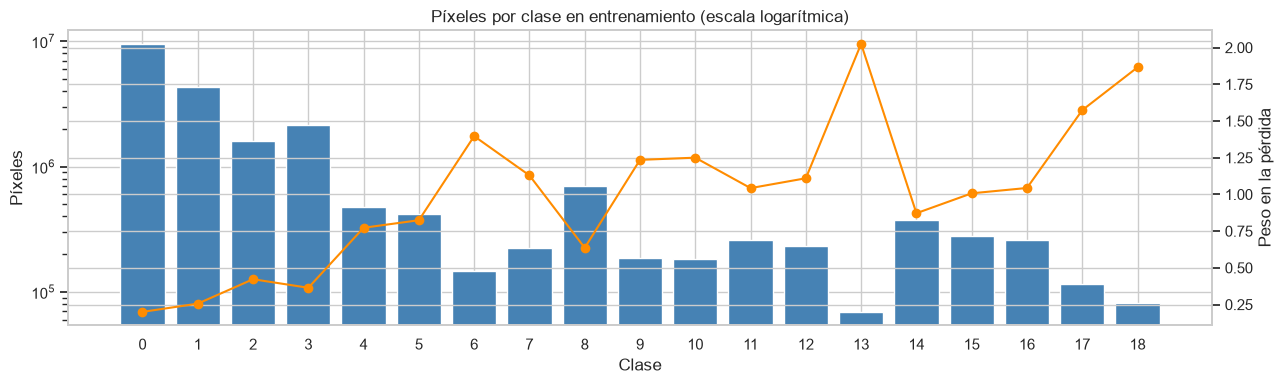

In [11]:
# ==============================================================================
# 2.2 FRECUENCIAS DE CLASE Y PESOS PARA LA PÉRDIDA
# ==============================================================================
conteo = np.zeros(NUM_CLASSES + 1, np.int64)
for pid in tqdm(IDS["train"], desc="Frecuencias de clase"):
    y = np.load(ruta_target(pid))[0].astype(np.int64)
    assert y.min() >= 0 and y.max() <= VOID_LABEL, f"Etiquetas fuera de rango en {pid}"
    conteo += np.bincount(y.ravel(), minlength=NUM_CLASSES + 1)

validos = conteo[:NUM_CLASSES].astype(np.float64)
freq = validos / validos.sum()
pesos = np.where(freq > 0, 1.0 / np.sqrt(np.maximum(freq, 1e-12)), 0.0)
pesos = pesos / pesos[freq > 0].mean()
pesos = np.where(freq > 0, np.clip(pesos, PESO_MIN, PESO_MAX), 0.0)
CLASS_WEIGHTS = torch.tensor(pesos, dtype=torch.float32)

tabla_clases = pd.DataFrame({
    "Clase": range(NUM_CLASSES), "Nombre": [NOMBRES_CLASES[i] for i in range(NUM_CLASSES)],
    "Píxeles train": conteo[:NUM_CLASSES], "% train": (100 * freq).round(3), "Peso": pesos.round(3)})
display(tabla_clases)
presentes = validos[validos > 0]
print(f"Píxeles Void (ignorados): {conteo[VOID_LABEL]:,} ({100 * conteo[VOID_LABEL] / conteo.sum():.1f}% del total)")
print(f"Desbalance entre clases presentes (máx/mín): {presentes.max() / presentes.min():.0f}:1")
print("Clases sin píxeles en entrenamiento:", np.where(validos == 0)[0].tolist())

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(range(NUM_CLASSES), np.maximum(validos, 1), color="steelblue")
ax.set_yscale("log"); ax.set_xticks(range(NUM_CLASSES))
ax.set(title="Píxeles por clase en entrenamiento (escala logarítmica)", xlabel="Clase", ylabel="Píxeles")
ax2 = ax.twinx(); ax2.plot(range(NUM_CLASSES), pesos, "o-", color="darkorange"); ax2.set_ylabel("Peso en la pérdida")
plt.tight_layout(); plt.show()

### 2.3 Dataset y DataLoaders

- Cada muestra es un **parche completo** `(T, 10, 128, 128)` con sus fechas en días desde 2018-09-01, que el *positional encoding* de la atención temporal utiliza como posiciones.
- **Entrenamiento:** submuestreo aleatorio y ordenado de `T_TRAIN` fechas (solo se leen del disco las fechas elegidas) y una de las 8 transformaciones del grupo diédrico (rotaciones de 90° y giros), aplicada igual a imagen y máscara.
- **Validación y prueba:** todas las fechas, sin aumentación. Los parches con menos fechas se rellenan con ceros al final de la secuencia (`pad_value = 0`); el modelo detecta y enmascara esas fechas.

In [12]:
# ==============================================================================
# 2.3 DATASET Y DATALOADERS
# ==============================================================================
class PastisDataset(Dataset):
    def __init__(self, ids, train, t_train, mean, std):
        self.ids, self.train, self.t_train = list(ids), train, t_train
        self.mean = mean.reshape(1, 10, 1, 1).astype(np.float32)
        self.std = std.reshape(1, 10, 1, 1).astype(np.float32)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        pid = self.ids[i]
        x = np.load(ruta_s2(pid), mmap_mode="r")                     # (T, 10, H, W), sin leer aún
        y = np.load(ruta_target(pid))[0].astype(np.int64)            # (H, W): 0..18 y 19 = Void
        d = DATES[pid].copy()
        if self.train:
            # Generador derivado del RNG de torch: distinto por worker y por época, reproducible con SEED.
            rng = np.random.default_rng(int(torch.randint(0, 2 ** 31 - 1, (1,)).item()))
            if x.shape[0] > self.t_train:
                idx = np.sort(rng.choice(x.shape[0], self.t_train, replace=False))
                x, d = x[idx], d[idx]                                # solo lee esas fechas
            x = np.asarray(x, dtype=np.float32)
            k = int(rng.integers(4))
            x, y = np.rot90(x, k, axes=(2, 3)), np.rot90(y, k, axes=(0, 1))
            if rng.random() < 0.5:
                x, y = x[..., ::-1], y[..., ::-1]
        else:
            x = np.asarray(x, dtype=np.float32)
        x = (x - self.mean) / self.std
        return (torch.from_numpy(np.ascontiguousarray(x)),
                torch.from_numpy(np.ascontiguousarray(y)),
                torch.from_numpy(d))

def pad_collate(batch):
    # Rellena con ceros la dimensión temporal hasta la serie más larga del lote.
    T = max(b[0].shape[0] for b in batch)
    xs, ys, ds = [], [], []
    for x, y, d in batch:
        p = T - x.shape[0]
        xs.append(F.pad(x, (0, 0, 0, 0, 0, 0, 0, p)))
        ds.append(F.pad(d, (0, p))); ys.append(y)
    return torch.stack(xs), torch.stack(ys), torch.stack(ds)

def make_loader(ids, train, batch_size, t_train=None):
    ds = PastisDataset(ids, train, t_train, MEAN, STD)
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, num_workers=NUM_WORKERS,
                      collate_fn=pad_collate, pin_memory=(DEVICE.type == "cuda"), drop_last=train,
                      persistent_workers=NUM_WORKERS > 0, generator=g)

# Comprobación rápida de una muestra (sin aumentación)
_x, _y, _d = PastisDataset(IDS["train"][:1], False, None, MEAN, STD)[0]
print("x:", tuple(_x.shape), "| y:", tuple(_y.shape), "| fechas:", _d[:5].tolist(), "...")
print(f"x normalizada: media={_x.mean():.2f}, desv={_x.std():.2f} | clases en y: {sorted(torch.unique(_y).tolist())}")

x: (43, 10, 128, 128) | y: (128, 128) | fechas: [23, 28, 33, 38, 48] ...
x normalizada: media=0.13, desv=0.93 | clases en y: [0, 1, 2, 3, 4, 6, 12, 13, 19]


## 3. Modelo U-TAE

**U-TAE** (*U-Net with Temporal Attention Encoder*) procesa cada fecha con un codificador convolucional compartido de cuatro etapas. En la resolución más baja, un **L-TAE** (atención temporal ligera con 16 cabezas y una consulta aprendida por cabeza) resume la serie en un solo mapa de características usando las fechas como posiciones. Las mismas máscaras de atención se re-muestrean para agregar en el tiempo las conexiones de salto (`att_group`), y un decodificador tipo U-Net produce el mapa de 19 clases.

**Implementación.** El código siguiente reproduce `src/backbones/utae.py`, `ltae.py` y `positional_encoding.py` del repositorio oficial [VSainteuf/utae-paps](https://github.com/VSainteuf/utae-paps) (licencia MIT, © Vivien Sainte Fare Garnot), con la configuración por defecto del artículo. Se integra en el notebook para no depender de `git clone` (en Kaggle el acceso a Internet puede estar desactivado). La única modificación es de eficiencia: el original ejecuta una pasada adicional sobre un tensor de ceros en cada bloque solo para conocer la forma de salida; aquí la forma se obtiene de la pasada real, lo que ahorra memoria y tiempo sin cambiar el resultado. La única diferencia de configuración es la salida: 19 clases en lugar de 20, porque Void se ignora en lugar de modelarse.

In [13]:
# ==============================================================================
# 3.1 IMPLEMENTACIÓN DE U-TAE (adaptada de VSainteuf/utae-paps, licencia MIT)
# ==============================================================================
# MIT License — Copyright (c) Vivien Sainte Fare Garnot. Ver github.com/VSainteuf/utae-paps

class PositionalEncoder(nn.Module):
    def __init__(self, d, T=1000, repeat=None, offset=0):
        super().__init__()
        self.d, self.T, self.repeat = d, T, repeat
        self.denom = torch.pow(T, 2 * (torch.arange(offset, offset + d).float() // 2) / d)
        self.updated_location = False

    def forward(self, batch_positions):
        if not self.updated_location:
            self.denom = self.denom.to(batch_positions.device)
            self.updated_location = True
        sinusoid_table = batch_positions[:, :, None] / self.denom[None, None, :]   # B x T x C
        sinusoid_table[:, :, 0::2] = torch.sin(sinusoid_table[:, :, 0::2])
        sinusoid_table[:, :, 1::2] = torch.cos(sinusoid_table[:, :, 1::2])
        if self.repeat is not None:
            sinusoid_table = torch.cat([sinusoid_table for _ in range(self.repeat)], dim=-1)
        return sinusoid_table


class ScaledDotProductAttention(nn.Module):
    def __init__(self, temperature, attn_dropout=0.1):
        super().__init__()
        self.temperature = temperature
        self.dropout = nn.Dropout(attn_dropout)
        self.softmax = nn.Softmax(dim=2)

    def forward(self, q, k, v, pad_mask=None):
        attn = torch.matmul(q.unsqueeze(1), k.transpose(1, 2)) / self.temperature
        if pad_mask is not None:
            attn = attn.masked_fill(pad_mask.unsqueeze(1), -1e3)
        attn = self.dropout(self.softmax(attn))
        return torch.matmul(attn, v), attn


class MultiHeadAttention(nn.Module):
    def __init__(self, n_head, d_k, d_in):
        super().__init__()
        self.n_head, self.d_k, self.d_in = n_head, d_k, d_in
        self.Q = nn.Parameter(torch.zeros((n_head, d_k))).requires_grad_(True)
        nn.init.normal_(self.Q, mean=0, std=np.sqrt(2.0 / d_k))
        self.fc1_k = nn.Linear(d_in, n_head * d_k)
        nn.init.normal_(self.fc1_k.weight, mean=0, std=np.sqrt(2.0 / d_k))
        self.attention = ScaledDotProductAttention(temperature=np.power(d_k, 0.5))

    def forward(self, v, pad_mask=None):
        d_k, d_in, n_head = self.d_k, self.d_in, self.n_head
        sz_b, seq_len, _ = v.size()
        q = torch.stack([self.Q for _ in range(sz_b)], dim=1).view(-1, d_k)        # (n*b) x d_k
        k = self.fc1_k(v).view(sz_b, seq_len, n_head, d_k)
        k = k.permute(2, 0, 1, 3).contiguous().view(-1, seq_len, d_k)               # (n*b) x lk x dk
        if pad_mask is not None:
            pad_mask = pad_mask.repeat((n_head, 1))
        v = torch.stack(v.split(v.shape[-1] // n_head, dim=-1)).view(n_head * sz_b, seq_len, -1)
        output, attn = self.attention(q, k, v, pad_mask=pad_mask)
        attn = attn.view(n_head, sz_b, 1, seq_len).squeeze(dim=2)
        output = output.view(n_head, sz_b, 1, d_in // n_head).squeeze(dim=2)
        return output, attn


class LTAE2d(nn.Module):
    def __init__(self, in_channels=128, n_head=16, d_k=4, mlp=[256, 128], dropout=0.2,
                 d_model=256, T=1000, return_att=False, positional_encoding=True):
        super().__init__()
        self.in_channels, self.mlp, self.return_att, self.n_head = in_channels, copy.deepcopy(mlp), return_att, n_head
        if d_model is not None:
            self.d_model = d_model
            self.inconv = nn.Conv1d(in_channels, d_model, 1)
        else:
            self.d_model, self.inconv = in_channels, None
        assert self.mlp[0] == self.d_model
        self.positional_encoder = (PositionalEncoder(self.d_model // n_head, T=T, repeat=n_head)
                                   if positional_encoding else None)
        self.attention_heads = MultiHeadAttention(n_head=n_head, d_k=d_k, d_in=self.d_model)
        self.in_norm = nn.GroupNorm(num_groups=n_head, num_channels=self.in_channels)
        self.out_norm = nn.GroupNorm(num_groups=n_head, num_channels=mlp[-1])
        layers = []
        for i in range(len(self.mlp) - 1):
            layers.extend([nn.Linear(self.mlp[i], self.mlp[i + 1]), nn.BatchNorm1d(self.mlp[i + 1]), nn.ReLU()])
        self.mlp = nn.Sequential(*layers)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, batch_positions=None, pad_mask=None):
        sz_b, seq_len, d, h, w = x.shape
        if pad_mask is not None:
            pad_mask = pad_mask.unsqueeze(-1).repeat((1, 1, h)).unsqueeze(-1).repeat((1, 1, 1, w))   # BxTxHxW
            pad_mask = pad_mask.permute(0, 2, 3, 1).contiguous().view(sz_b * h * w, seq_len)
        out = x.permute(0, 3, 4, 1, 2).contiguous().view(sz_b * h * w, seq_len, d)
        out = self.in_norm(out.permute(0, 2, 1)).permute(0, 2, 1)
        if self.inconv is not None:
            out = self.inconv(out.permute(0, 2, 1)).permute(0, 2, 1)
        if self.positional_encoder is not None:
            bp = batch_positions.unsqueeze(-1).repeat((1, 1, h)).unsqueeze(-1).repeat((1, 1, 1, w))
            bp = bp.permute(0, 2, 3, 1).contiguous().view(sz_b * h * w, seq_len)
            out = out + self.positional_encoder(bp)
        out, attn = self.attention_heads(out, pad_mask=pad_mask)
        out = out.permute(1, 0, 2).contiguous().view(sz_b * h * w, -1)             # concatena cabezas
        out = self.dropout(self.mlp(out))
        out = self.out_norm(out) if self.out_norm is not None else out
        out = out.view(sz_b, h, w, -1).permute(0, 3, 1, 2)
        attn = attn.view(self.n_head, sz_b, h, w, seq_len).permute(0, 1, 4, 2, 3)   # head x b x t x h x w
        return (out, attn) if self.return_att else out


class TemporallySharedBlock(nn.Module):
    # Aplica el mismo bloque convolucional a todas las fechas (B*T imágenes), sin procesar las de relleno.
    def __init__(self, pad_value=None):
        super().__init__()
        self.pad_value = pad_value

    def smart_forward(self, input):
        if input.dim() == 4:
            return self.forward(input)
        b, t, c, h, w = input.shape
        out = input.reshape(b * t, c, h, w)
        if self.pad_value is not None:
            pad_mask = (out == self.pad_value).all(dim=-1).all(dim=-1).all(dim=-1)
            if pad_mask.any():
                # Cambio respecto al original: sin pasada extra sobre ceros para conocer la forma de salida.
                validas = self.forward(out[~pad_mask])
                temp = validas.new_full((b * t,) + tuple(validas.shape[1:]), float(self.pad_value))
                temp[~pad_mask] = validas
                out = temp
            else:
                out = self.forward(out)
        else:
            out = self.forward(out)
        return out.view(b, t, *out.shape[1:])


class ConvLayer(nn.Module):
    def __init__(self, nkernels, norm="batch", k=3, s=1, p=1, n_groups=4, last_relu=True, padding_mode="reflect"):
        super().__init__()
        layers = []
        if norm == "batch":
            nl = nn.BatchNorm2d
        elif norm == "instance":
            nl = nn.InstanceNorm2d
        elif norm == "group":
            nl = lambda num_feats: nn.GroupNorm(num_channels=num_feats, num_groups=n_groups)
        else:
            nl = None
        for i in range(len(nkernels) - 1):
            layers.append(nn.Conv2d(nkernels[i], nkernels[i + 1], kernel_size=k, padding=p, stride=s,
                                    padding_mode=padding_mode))
            if nl is not None:
                layers.append(nl(nkernels[i + 1]))
            if last_relu or i < len(nkernels) - 2:
                layers.append(nn.ReLU())
        self.conv = nn.Sequential(*layers)

    def forward(self, input):
        return self.conv(input)


class ConvBlock(TemporallySharedBlock):
    def __init__(self, nkernels, pad_value=None, norm="batch", last_relu=True, padding_mode="reflect"):
        super().__init__(pad_value=pad_value)
        self.conv = ConvLayer(nkernels=nkernels, norm=norm, last_relu=last_relu, padding_mode=padding_mode)

    def forward(self, input):
        return self.conv(input)


class DownConvBlock(TemporallySharedBlock):
    def __init__(self, d_in, d_out, k, s, p, pad_value=None, norm="batch", padding_mode="reflect"):
        super().__init__(pad_value=pad_value)
        self.down = ConvLayer(nkernels=[d_in, d_in], norm=norm, k=k, s=s, p=p, padding_mode=padding_mode)
        self.conv1 = ConvLayer(nkernels=[d_in, d_out], norm=norm, padding_mode=padding_mode)
        self.conv2 = ConvLayer(nkernels=[d_out, d_out], norm=norm, padding_mode=padding_mode)

    def forward(self, input):
        out = self.conv1(self.down(input))
        return out + self.conv2(out)


class UpConvBlock(nn.Module):
    def __init__(self, d_in, d_out, k, s, p, norm="batch", d_skip=None, padding_mode="reflect"):
        super().__init__()
        d = d_out if d_skip is None else d_skip
        self.skip_conv = nn.Sequential(nn.Conv2d(d, d, kernel_size=1), nn.BatchNorm2d(d), nn.ReLU())
        self.up = nn.Sequential(nn.ConvTranspose2d(d_in, d_out, kernel_size=k, stride=s, padding=p),
                                nn.BatchNorm2d(d_out), nn.ReLU())
        self.conv1 = ConvLayer(nkernels=[d_out + d, d_out], norm=norm, padding_mode=padding_mode)
        self.conv2 = ConvLayer(nkernels=[d_out, d_out], norm=norm, padding_mode=padding_mode)

    def forward(self, input, skip):
        out = torch.cat([self.up(input), self.skip_conv(skip)], dim=1)
        out = self.conv1(out)
        return out + self.conv2(out)


class Temporal_Aggregator(nn.Module):
    # Solo se usa el modo 'att_group' (configuración del artículo).
    def __init__(self, mode="att_group"):
        super().__init__()
        assert mode == "att_group"
        self.mode = mode

    def forward(self, x, pad_mask=None, attn_mask=None):
        n_heads, b, t, h, w = attn_mask.shape
        attn = attn_mask.view(n_heads * b, t, h, w)
        if x.shape[-2] > w:
            attn = nn.Upsample(size=x.shape[-2:], mode="bilinear", align_corners=False)(attn)
        else:
            attn = nn.AvgPool2d(kernel_size=w // x.shape[-2])(attn)
        attn = attn.view(n_heads, b, t, *x.shape[-2:])
        if pad_mask is not None and pad_mask.any():
            attn = attn * (~pad_mask).float()[None, :, :, None, None]
        out = torch.stack(x.chunk(n_heads, dim=2))          # h x B x T x C/h x H x W
        out = attn[:, :, :, None, :, :] * out
        out = out.sum(dim=2)                                # suma temporal -> h x B x C/h x H x W
        return torch.cat([group for group in out], dim=1)   # B x C x H x W


class UTAE(nn.Module):
    def __init__(self, input_dim, encoder_widths=[64, 64, 64, 128], decoder_widths=[32, 32, 64, 128],
                 out_conv=[32, 20], str_conv_k=4, str_conv_s=2, str_conv_p=1, agg_mode="att_group",
                 encoder_norm="group", n_head=16, d_model=256, d_k=4, pad_value=0, padding_mode="reflect"):
        super().__init__()
        self.n_stages = len(encoder_widths)
        self.pad_value = pad_value
        assert len(encoder_widths) == len(decoder_widths) and encoder_widths[-1] == decoder_widths[-1]
        self.in_conv = ConvBlock(nkernels=[input_dim] + [encoder_widths[0], encoder_widths[0]],
                                 pad_value=pad_value, norm=encoder_norm, padding_mode=padding_mode)
        self.down_blocks = nn.ModuleList(
            DownConvBlock(d_in=encoder_widths[i], d_out=encoder_widths[i + 1], k=str_conv_k, s=str_conv_s,
                          p=str_conv_p, pad_value=pad_value, norm=encoder_norm, padding_mode=padding_mode)
            for i in range(self.n_stages - 1))
        self.up_blocks = nn.ModuleList(
            UpConvBlock(d_in=decoder_widths[i], d_out=decoder_widths[i - 1], d_skip=encoder_widths[i - 1],
                        k=str_conv_k, s=str_conv_s, p=str_conv_p, norm="batch", padding_mode=padding_mode)
            for i in range(self.n_stages - 1, 0, -1))
        self.temporal_encoder = LTAE2d(in_channels=encoder_widths[-1], d_model=d_model, n_head=n_head,
                                       mlp=[d_model, encoder_widths[-1]], return_att=True, d_k=d_k)
        self.temporal_aggregator = Temporal_Aggregator(mode=agg_mode)
        self.out_conv = ConvBlock(nkernels=[decoder_widths[0]] + out_conv, padding_mode=padding_mode)

    def forward(self, input, batch_positions=None, return_att=False):
        pad_mask = (input == self.pad_value).all(dim=-1).all(dim=-1).all(dim=-1)   # B x T
        out = self.in_conv.smart_forward(input)
        feature_maps = [out]
        for i in range(self.n_stages - 1):                       # codificador espacial
            out = self.down_blocks[i].smart_forward(feature_maps[-1])
            feature_maps.append(out)
        out, att = self.temporal_encoder(feature_maps[-1], batch_positions=batch_positions, pad_mask=pad_mask)
        for i in range(self.n_stages - 1):                       # decodificador espacial
            skip = self.temporal_aggregator(feature_maps[-(i + 2)], pad_mask=pad_mask, attn_mask=att)
            out = self.up_blocks[i](out, skip)
        out = self.out_conv(out)
        return (out, att) if return_att else out


def crear_modelo():
    return UTAE(input_dim=10, encoder_widths=[64, 64, 64, 128], decoder_widths=[32, 32, 64, 128],
                out_conv=[32, NUM_CLASSES], str_conv_k=4, str_conv_s=2, str_conv_p=1,
                agg_mode="att_group", encoder_norm="group", n_head=16, d_model=256, d_k=4,
                pad_value=0, padding_mode="reflect")

_m = crear_modelo()
print(f"Parámetros entrenables: {sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

Parámetros entrenables: 1,086,969


## 4. Función de Pérdida y Métricas

**Pérdida** = cross-entropy ponderada por clase (ignorando Void) + `DICE_WEIGHT` × Dice suave. El Dice se promedia sobre las clases presentes en el lote y también excluye Void. La cross-entropy aporta gradientes estables por píxel; el Dice evita que el modelo se conforme con las clases que ocupan más superficie.

**Métricas.** Se acumula una matriz de confusión 19×19 sobre **todos los píxeles válidos** de los parches evaluados. A partir de ella se calculan Accuracy, IoU y F1 por clase, y sus macro promedios sobre las 19 clases (las clases sin píxeles reales ni predichos cuentan 0, como en el Avance 5).

In [14]:
# ==============================================================================
# 4.1 PÉRDIDA (CE PONDERADA + DICE) Y MÉTRICAS
# ==============================================================================
ce_loss = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), ignore_index=VOID_LABEL)

def dice_loss(logits, y, eps=1e-6):
    valid = (y != VOID_LABEL)
    probs = logits.softmax(dim=1) * valid.unsqueeze(1)
    onehot = F.one_hot(y.clamp(max=NUM_CLASSES - 1), NUM_CLASSES).permute(0, 3, 1, 2).float() * valid.unsqueeze(1)
    inter = (probs * onehot).sum(dim=(0, 2, 3))
    denom = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    presente = onehot.sum(dim=(0, 2, 3)) > 0
    dice = (2 * inter + eps) / (denom + eps)
    return 1 - dice[presente].mean() if presente.any() else logits.sum() * 0

def criterio(logits, y):
    logits = logits.float()
    loss = ce_loss(logits, y)
    if DICE_WEIGHT > 0:
        loss = loss + DICE_WEIGHT * dice_loss(logits, y)
    return loss

def actualizar_confusion(conf, pred, y):
    m = y != VOID_LABEL
    idx = y[m] * NUM_CLASSES + pred[m]
    conf += torch.bincount(idx, minlength=NUM_CLASSES ** 2).view(NUM_CLASSES, NUM_CLASSES)

def metricas_desde_confusion(conf):
    conf = np.asarray(conf, dtype=np.float64)
    tp = np.diag(conf); real = conf.sum(1); pred = conf.sum(0)
    union = real + pred - tp
    iou = np.where(union > 0, tp / np.maximum(union, 1), 0.0)
    f1 = np.where(real + pred > 0, 2 * tp / np.maximum(real + pred, 1), 0.0)
    return {"Accuracy": float(tp.sum() / max(conf.sum(), 1)), "mIoU": float(iou.mean()),
            "Macro F1": float(f1.mean()), "iou": iou, "f1": f1, "conf": conf}

# Prueba del cálculo con un caso conocido: predicción perfecta en 2 clases -> IoU=F1=1 en ellas, 0 en el resto.
_c = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
actualizar_confusion(_c, torch.tensor([0, 1, 1, 0]), torch.tensor([0, 1, 1, 19]))
_r = metricas_desde_confusion(_c.numpy())
assert _r["Accuracy"] == 1.0 and abs(_r["mIoU"] - 2 / 19) < 1e-9 and abs(_r["Macro F1"] - 2 / 19) < 1e-9
print("Pérdida y métricas definidas; verificación del cálculo: CORRECTA")

Pérdida y métricas definidas; verificación del cálculo: CORRECTA


## 5. Ajuste de Memoria y Entrenamiento

### 5.1 Selección automática de `BATCH_SIZE` y `T_TRAIN`

La memoria de U-TAE crece casi linealmente con `BATCH_SIZE × T_TRAIN`, porque el codificador procesa cada fecha a 128×128 píxeles. En lugar de fijar valores a mano, se prueba una pasada completa (adelante y atrás) con datos aleatorios para varias configuraciones, de la preferida a la más modesta, y se elige la primera que usa menos del 85% de la VRAM. Se prioriza conservar las 32 fechas definidas en el diseño; si el lote resultante es menor que `EFFECTIVE_BATCH`, se **acumulan gradientes** para mantener el mismo lote efectivo.

Referencia medida en la RTX 4050 portátil (6 GB, bf16): `BATCH_SIZE=4, T_TRAIN=32` necesita ≈6.2 GB (no cabe) y `BATCH_SIZE=2, T_TRAIN=32` ≈3.1 GB (cabe, con acumulación ×2). En una GPU de 16 GB (T4) se espera que quepa `BATCH_SIZE=4, T_TRAIN=32`. El resultado real de cada máquina se imprime abajo.

In [15]:
# ==============================================================================
# 5.1 SELECCIÓN AUTOMÁTICA DE BATCH_SIZE / T_TRAIN SEGÚN LA VRAM
# ==============================================================================
CANDIDATOS = [(4, T_TRAIN_OBJETIVO), (2, T_TRAIN_OBJETIVO), (1, T_TRAIN_OBJETIVO), (1, 24), (1, 16)]

def memoria_pico(bs, t):
    # Pasada adelante/atrás con datos aleatorios; devuelve GB pico o None si no cabe.
    m = crear_modelo().to(DEVICE).train()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-4)
    try:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        x = torch.randn(bs, t, 10, 128, 128, device=DEVICE)
        d = torch.sort(torch.randint(0, 365, (bs, t), device=DEVICE), dim=1).values
        y = torch.randint(0, NUM_CLASSES + 1, (bs, 128, 128), device=DEVICE)
        for _ in range(2):
            with autocast():
                logits = m(x, batch_positions=d)
            criterio(logits, y).backward(); opt.step(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 1024 ** 3
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        del m, opt
        torch.cuda.empty_cache()

if DEVICE.type == "cuda" and (BATCH_SIZE is None or T_TRAIN is None):
    registro_mem = []
    for bs, t in CANDIDATOS:
        pico = memoria_pico(bs, t)
        cabe = pico is not None and pico < 0.85 * VRAM_GB
        registro_mem.append({"BATCH_SIZE": bs, "T_TRAIN": t,
                             "Memoria pico (GB)": None if pico is None else round(pico, 2), "Cabe": cabe})
        if cabe:
            BATCH_SIZE, T_TRAIN = bs, t
            break
    display(pd.DataFrame(registro_mem))
    if BATCH_SIZE is None:
        raise RuntimeError("Ninguna configuración cabe en la GPU; reduce T_TRAIN_OBJETIVO.")
elif BATCH_SIZE is None or T_TRAIN is None:
    BATCH_SIZE, T_TRAIN = 1, 16           # CPU: solo para pruebas

ACCUM_STEPS = max(1, math.ceil(EFFECTIVE_BATCH / BATCH_SIZE))
EVAL_BATCH = 2 if VRAM_GB >= 12 else 1    # en evaluación se usan todas las fechas (hasta ~61)
print(f"Configuración elegida: BATCH_SIZE={BATCH_SIZE}, T_TRAIN={T_TRAIN}, "
      f"acumulación={ACCUM_STEPS} (lote efectivo {BATCH_SIZE * ACCUM_STEPS}), lote de evaluación={EVAL_BATCH}")

train_loader = make_loader(IDS["train"], True, BATCH_SIZE, T_TRAIN)
val_loader = make_loader(IDS["val"], False, EVAL_BATCH)

,BATCH_SIZE,T_TRAIN,Memoria pico (GB),Cabe
0,4,32,6.16,False
1,2,32,3.10,True


Configuración elegida: BATCH_SIZE=2, T_TRAIN=32, acumulación=2 (lote efectivo 4), lote de evaluación=1


### 5.2 Entrenamiento con checkpoints y reanudación

- **Optimizador:** AdamW (`lr = 1e-3`), calentamiento lineal de 2 épocas y decaimiento coseno hasta 1% del valor inicial, recorte de gradiente y precisión mixta (bf16 o fp16 según la GPU).
- **Selección:** al final de cada época se evalúa el fold 4 completo; `best.pt` guarda el modelo con mayor **mIoU de validación**. La parada temprana ocurre tras `PATIENCE` épocas sin mejora.
- **Reanudación:** en cada época se guarda `last.pt` (modelo, optimizador, *scheduler*, escalador, estados aleatorios e historial) mediante escritura atómica. Volver a ejecutar el notebook continúa desde ahí.
- **Kaggle:** las sesiones con GPU duran como máximo 12 h y `/kaggle/working` solo se conserva al guardar una versión. El bucle se detiene solo antes de `MAX_HORAS_SESION`. Para continuar en otra sesión, se añade la salida de la versión anterior del notebook como *Input*; esta celda busca ahí `utae_ckpt/last.pt` y lo copia antes de reanudar.

In [16]:
# ==============================================================================
# 5.2 BUCLE DE ENTRENAMIENTO CON CHECKPOINTS Y REANUDACIÓN
# ==============================================================================
@torch.no_grad()
def evaluar(model, loader, desc="Evaluando", tta=False):
    model.eval()
    conf = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long, device=DEVICE)
    perdida, n = 0.0, 0
    for x, y, d in tqdm(loader, desc=desc, leave=False):
        x, y, d = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True), d.to(DEVICE, non_blocking=True)
        logits = predecir_logits(model, x, d, tta)
        perdida += criterio(logits, y).item() * x.shape[0]; n += x.shape[0]
        actualizar_confusion(conf, logits.argmax(1), y)
    r = metricas_desde_confusion(conf.cpu().numpy()); r["loss"] = perdida / max(n, 1)
    return r

def predecir_logits(model, x, d, tta=False):
    # Sin TTA: una pasada. Con TTA: promedio de probabilidades sobre las 8 transformaciones diédricas.
    with autocast():
        if not tta:
            return model(x, batch_positions=d).float()
        acumulado = 0
        for k in range(4):
            for flip in (False, True):
                xt = torch.rot90(x, k, dims=(-2, -1))
                xt = torch.flip(xt, dims=(-1,)) if flip else xt
                p = model(xt, batch_positions=d).float().softmax(1)
                p = torch.flip(p, dims=(-1,)) if flip else p
                acumulado = acumulado + torch.rot90(p, -k, dims=(-2, -1))
        return torch.log(acumulado / 8 + 1e-8)

def guardar_atomico(obj, ruta):
    tmp = Path(str(ruta) + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, ruta)

last_path, best_path = CKPT_DIR / "last.pt", CKPT_DIR / "best.pt"

# Kaggle: recuperar checkpoints de una versión anterior añadida como Input.
if EN_KAGGLE and not last_path.exists():
    previos = sorted(glob.glob("/kaggle/input/**/utae_ckpt/last.pt", recursive=True))
    if previos:
        origen = Path(previos[0]).parent
        for nombre in ("last.pt", "best.pt"):
            if (origen / nombre).exists():
                shutil.copy2(origen / nombre, CKPT_DIR / nombre)
        for extra in ("normalizacion.json", "historial_entrenamiento.csv"):
            if (origen.parent / extra).exists() and not (WORK_DIR / extra).exists():
                shutil.copy2(origen.parent / extra, WORK_DIR / extra)
        print("Checkpoints recuperados de", origen)

fijar_semillas(SEED)
model = crear_modelo().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
pasos_por_epoca = max(1, len(train_loader) // ACCUM_STEPS)
total_pasos, pasos_warmup = EPOCHS * pasos_por_epoca, WARMUP_EPOCHS * pasos_por_epoca

def factor_lr(paso):
    if paso < pasos_warmup:
        return (paso + 1) / pasos_warmup
    prog = min(1.0, (paso - pasos_warmup) / max(1, total_pasos - pasos_warmup))
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, factor_lr)
scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))

historial, mejor_miou, epoca_ini, sin_mejora, terminado = [], -1.0, 0, 0, False
if last_path.exists():
    ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
    scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"])
    historial, mejor_miou = ck["historial"], ck["mejor_miou"]
    epoca_ini, sin_mejora, terminado = ck["epoca"] + 1, ck["sin_mejora"], ck.get("terminado", False)
    torch.set_rng_state(ck["rng_torch"].cpu()); np.random.set_state(ck["rng_numpy"]); random.setstate(ck["rng_python"])
    if ck.get("config", {}).get("BATCH_SIZE") not in (None, BATCH_SIZE):
        print("AVISO: el checkpoint se entrenó con otro BATCH_SIZE; se continúa con", BATCH_SIZE)
    print(f"Reanudando desde la época {epoca_ini + 1} (mejor mIoU val = {mejor_miou:.4f})")

inicio_sesion = time.time()
for epoca in range(epoca_ini, EPOCHS):
    if terminado:
        break
    model.train(); t0 = time.time(); perdida_ep, nb = 0.0, 0
    optimizer.zero_grad(set_to_none=True)
    for i, (x, y, d) in enumerate(tqdm(train_loader, desc=f"Época {epoca + 1}/{EPOCHS}", leave=False)):
        x, y, d = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True), d.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x, batch_positions=d)
        loss = criterio(logits, y)
        if not torch.isfinite(loss):
            print("Pérdida no finita; se omite el lote."); optimizer.zero_grad(set_to_none=True); continue
        scaler.scale(loss / ACCUM_STEPS).backward()
        perdida_ep += loss.item(); nb += 1
        if (i + 1) % ACCUM_STEPS == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(set_to_none=True); scheduler.step()

    r = evaluar(model, val_loader, "Validación")
    historial.append({"epoca": epoca + 1, "loss_train": perdida_ep / max(nb, 1), "loss_val": r["loss"],
                      "val_miou": r["mIoU"], "val_f1": r["Macro F1"], "val_acc": r["Accuracy"],
                      "lr": optimizer.param_groups[0]["lr"], "seg": time.time() - t0})
    mejora = r["mIoU"] > mejor_miou
    if mejora:
        mejor_miou, sin_mejora = r["mIoU"], 0
        guardar_atomico({"model": model.state_dict(), "epoca": epoca, "miou": r["mIoU"],
                         "mean": MEAN, "std": STD, "class_weights": pesos}, best_path)
    else:
        sin_mejora += 1
    terminado = sin_mejora >= PATIENCE or epoca + 1 == EPOCHS
    guardar_atomico({"model": model.state_dict(), "optimizer": optimizer.state_dict(),
                     "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(),
                     "historial": historial, "mejor_miou": mejor_miou, "epoca": epoca,
                     "sin_mejora": sin_mejora, "terminado": terminado,
                     "rng_torch": torch.get_rng_state(), "rng_numpy": np.random.get_state(),
                     "rng_python": random.getstate(),
                     "config": {"BATCH_SIZE": BATCH_SIZE, "T_TRAIN": T_TRAIN, "ACCUM_STEPS": ACCUM_STEPS}},
                    last_path)
    pd.DataFrame(historial).to_csv(WORK_DIR / "historial_entrenamiento.csv", index=False)
    h = historial[-1]
    print(f"Época {h['epoca']:03d} | loss {h['loss_train']:.3f}/{h['loss_val']:.3f} | val mIoU {h['val_miou']:.4f} "
          f"F1 {h['val_f1']:.4f} Acc {h['val_acc']:.4f} | lr {h['lr']:.2e} | {h['seg']:.0f}s"
          f"{'  ★ mejor' if mejora else ''}", flush=True)
    if sin_mejora >= PATIENCE:
        print(f"Parada temprana: {PATIENCE} épocas sin mejorar el mIoU de validación.")
    # Límite de tiempo por sesión (Kaggle): parar antes de que la plataforma corte la ejecución.
    if MAX_HORAS_SESION is not None and not terminado:
        transcurrido = (time.time() - inicio_sesion) / 3600
        if transcurrido + 1.5 * h["seg"] / 3600 > MAX_HORAS_SESION:
            print(f"Límite de sesión: {transcurrido:.1f} h. Guarda la versión y reanuda en una nueva sesión.")
            break

ENTRENAMIENTO_COMPLETO = terminado
print(f"Entrenamiento {'terminado' if terminado else 'PAUSADO (reanudar más tarde)'}. "
      f"Mejor mIoU de validación: {mejor_miou:.4f} | épocas registradas: {len(historial)}")

Época 1/100:   0%|          | 0/727 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Época 001 | loss 3.293/2.449 | val mIoU 0.2525 F1 0.3629 Acc 0.5896 | lr 5.01e-04 | 386s  ★ mejor


Época 2/100:   0%|          | 0/727 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Época 002 | loss 2.624/1.888 | val mIoU 0.4088 F1 0.5342 Acc 0.6952 | lr 1.00e-03 | 384s  ★ mejor


... (290 outputs left out)

Época 099 | loss 0.735/0.883 | val mIoU 0.6499 F1 0.7750 Acc 0.8317 | lr 1.03e-05 | 340s  ★ mejor


Época 100/100:   0%|          | 0/727 [00:00<?, ?it/s]

Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Época 100 | loss 0.729/0.894 | val mIoU 0.6456 F1 0.7714 Acc 0.8302 | lr 1.00e-05 | 340s
Entrenamiento terminado. Mejor mIoU de validación: 0.6499 | épocas registradas: 100


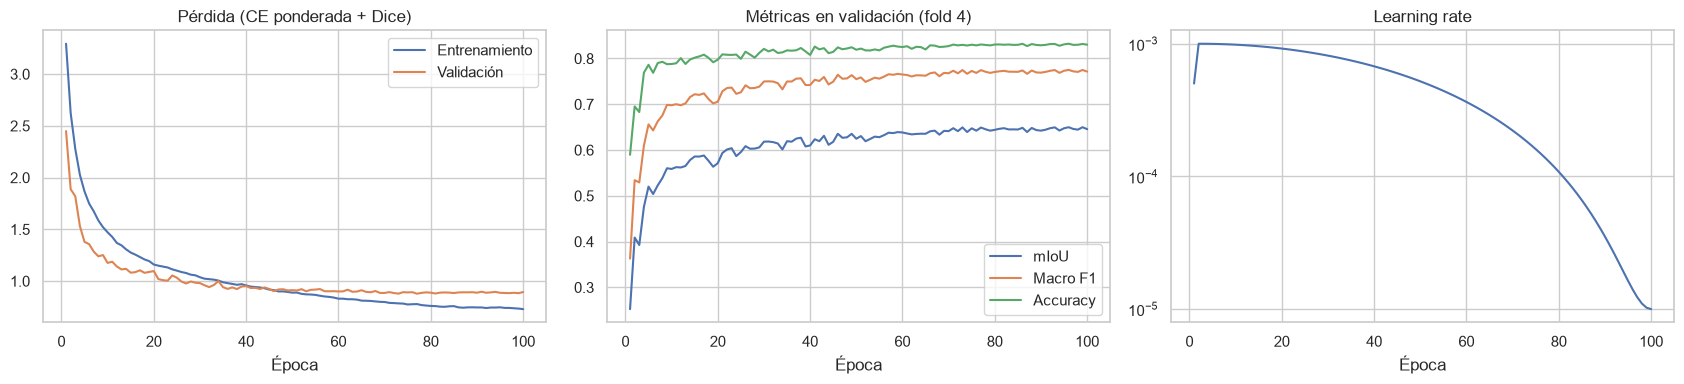

Tiempo medio por época: 6.1 min | mejor época: 99


In [17]:
# ==============================================================================
# 5.3 CURVAS DE ENTRENAMIENTO
# ==============================================================================
h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h.epoca, h.loss_train, label="Entrenamiento"); ax[0].plot(h.epoca, h.loss_val, label="Validación")
ax[0].set(title="Pérdida (CE ponderada + Dice)", xlabel="Época"); ax[0].legend()
ax[1].plot(h.epoca, h.val_miou, label="mIoU"); ax[1].plot(h.epoca, h.val_f1, label="Macro F1")
ax[1].plot(h.epoca, h.val_acc, label="Accuracy")
ax[1].set(title="Métricas en validación (fold 4)", xlabel="Época"); ax[1].legend()
ax[2].plot(h.epoca, h.lr); ax[2].set(title="Learning rate", xlabel="Época"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()
print(f"Tiempo medio por época: {h.seg.mean() / 60:.1f} min | mejor época: {int(h.loc[h.val_miou.idxmax(), 'epoca'])}")

### 5.4 Interpretación del Entrenamiento

Las curvas permiten revisar dos aspectos: si la pérdida de validación se separa de la de entrenamiento (sobreajuste) y en qué época se alcanza el máximo de mIoU de validación, que es la que define `best.pt`. Una pérdida de validación que sube mientras el mIoU todavía mejora no es contradictoria: el término Dice y los pesos de clase penalizan de forma distinta los errores en clases pequeñas, y lo que se usa para seleccionar el modelo es el mIoU.

## 6. Evaluación en Validación y Selección Final

Se carga `best.pt` y se evalúa el fold 4 con y sin **TTA** (promedio de las predicciones sobre las 8 rotaciones/giros del parche). El TTA solo se adopta si mejora el mIoU de **validación**; la decisión queda fija antes de mirar el fold 5.

In [18]:
# ==============================================================================
# 6.1 MEJOR CHECKPOINT Y DECISIÓN SOBRE TTA (SOLO CON VALIDACIÓN)
# ==============================================================================
ck = torch.load(best_path, map_location=DEVICE, weights_only=False)
model = crear_modelo().to(DEVICE); model.load_state_dict(ck["model"]); model.eval()
print(f"Mejor checkpoint: época {ck['epoca'] + 1} | mIoU de validación registrado: {ck['miou']:.4f}")

res_val = evaluar(model, val_loader, "Validación")
USAR_TTA = False
filas = [{"Inferencia": "Una pasada", "Accuracy": res_val["Accuracy"], "Macro F1": res_val["Macro F1"], "mIoU": res_val["mIoU"]}]
if PROBAR_TTA:
    res_val_tta = evaluar(model, val_loader, "Validación + TTA", tta=True)
    filas.append({"Inferencia": "TTA (8 transformaciones)", "Accuracy": res_val_tta["Accuracy"],
                  "Macro F1": res_val_tta["Macro F1"], "mIoU": res_val_tta["mIoU"]})
    if res_val_tta["mIoU"] > res_val["mIoU"]:
        USAR_TTA, res_val = True, res_val_tta
display(pd.DataFrame(filas).round(4))
print("Inferencia elegida con validación:", "TTA" if USAR_TTA else "una pasada")

por_clase_val = pd.DataFrame({"Clase": [NOMBRES_CLASES[i] for i in range(NUM_CLASSES)],
                              "IoU": res_val["iou"].round(4), "F1": res_val["f1"].round(4),
                              "Soporte (px)": res_val["conf"].sum(1).astype(int)})
display(por_clase_val)

Mejor checkpoint: época 99 | mIoU de validación registrado: 0.6499


Validación:   0%|          | 0/482 [00:00<?, ?it/s]

Validación + TTA:   0%|          | 0/482 [00:00<?, ?it/s]

,Inferencia,Accuracy,Macro F1,mIoU
0,Una pasada,0.8317,0.7750,0.6499
1,TTA (8 transformaciones),0.8323,0.7756,0.6507


Inferencia elegida con validación: TTA


,Clase,IoU,F1,Soporte (px)
0,Fondo,0.7288,0.8432,3158992
1,Pradera,0.6611,0.7960,1466003
2,Trigo blando de invierno,0.8376,0.9117,560680
3,Maíz,0.8737,0.9326,688289
4,Cebada de invierno,0.8311,0.9078,163392
5,Colza de invierno,0.8762,0.9340,129119
6,Cebada de primavera,0.5959,0.7468,53762
7,Girasol,0.7526,0.8588,81933
8,Vid,0.5337,0.6960,187477
9,Remolacha,0.8685,0.9296,71047


## 7. Evaluación del Modelo Seleccionado en Datos No Vistos (fold 5)

El modelo y el tipo de inferencia quedaron fijos en la sección 6. El fold 5 se evalúa **una sola vez**, sobre todos los píxeles válidos de los parches de prueba. Si el entrenamiento quedó en pausa por el límite de tiempo, esta sección no se ejecuta hasta completarlo.

In [19]:
# ==============================================================================
# 7.1 MÉTRICAS EN PRUEBA (PARCHES COMPLETOS)
# ==============================================================================
EJECUTAR_PRUEBA = EVALUAR_PRUEBA and ENTRENAMIENTO_COMPLETO
if not EJECUTAR_PRUEBA:
    print("Prueba NO evaluada: el entrenamiento no ha terminado o EVALUAR_PRUEBA=False.")
else:
    test_loader = make_loader(IDS["test"], False, EVAL_BATCH)
    res_test = evaluar(model, test_loader, "Prueba", tta=USAR_TTA)
    resumen = pd.DataFrame({"Partición": ["Validación (fold 4)", "Prueba (fold 5)"],
                            "Accuracy": [res_val["Accuracy"], res_test["Accuracy"]],
                            "Macro F1": [res_val["Macro F1"], res_test["Macro F1"]],
                            "mIoU": [res_val["mIoU"], res_test["mIoU"]]}).round(4)
    print("=== U-TAE — MÉTRICAS SOBRE PARCHES COMPLETOS ===")
    display(resumen)
    por_clase = pd.DataFrame({"Clase": [NOMBRES_CLASES[i] for i in range(NUM_CLASSES)],
                              "IoU": res_test["iou"].round(4), "F1": res_test["f1"].round(4),
                              "Soporte (px)": res_test["conf"].sum(1).astype(int)})
    display(por_clase)

Prueba:   0%|          | 0/496 [00:00<?, ?it/s]

=== U-TAE — MÉTRICAS SOBRE PARCHES COMPLETOS ===


,Partición,Accuracy,Macro F1,mIoU
0,Validación (fold 4),0.8323,0.7756,0.6507
1,Prueba (fold 5),0.8290,0.7703,0.6424


,Clase,IoU,F1,Soporte (px)
0,Fondo,0.7327,0.8458,3221643
1,Pradera,0.6459,0.7848,1487831
2,Trigo blando de invierno,0.8636,0.9268,580631
3,Maíz,0.8622,0.9260,620357
4,Cebada de invierno,0.8055,0.8923,171711
5,Colza de invierno,0.8792,0.9357,157965
6,Cebada de primavera,0.5717,0.7275,55308
7,Girasol,0.6986,0.8226,90899
8,Vid,0.5858,0.7388,219555
9,Remolacha,0.8459,0.9165,67567


### 7.2 Comparación con el Avance 5 sobre los mismos píxeles

Las métricas del Avance 5 se calcularon sobre una **muestra de 9,000 píxeles** (30 parches del fold 5 × 300 píxeles válidos), no sobre parches completos, así que comparar directamente con la tabla anterior mezclaría dos conjuntos de evaluación distintos. Como la muestra del Avance 5 es reproducible (semilla 42 para elegir parches y `42 + ID_PATCH` para elegir píxeles), aquí se **reconstruye exactamente** y U-TAE se evalúa sobre esos mismos 9,000 píxeles. La reconstrucción se valida comparando el conteo por clase con el que imprimió el Avance 5.

In [20]:
# ==============================================================================
# 7.2 COMPARACIÓN JUSTA CON EL AVANCE 5 (MISMOS 9,000 PÍXELES DEL FOLD 5)
# ==============================================================================
def ids_muestra_avance5():
    # Réplica de seleccionar_parches() del Avance 5: un único generador, en el orden train -> val -> test.
    g = np.random.default_rng(SEED)
    salida = {}
    for nombre, cantidad in [("train", 100), ("val", 30), ("test", 30)]:
        ids = np.sort(FOLDS_COMPLETOS[nombre]["ID_PATCH"].astype(int).to_numpy())
        salida[nombre] = sorted(int(p) for p in g.choice(ids, size=min(cantidad, len(ids)), replace=False))
    return salida

def pixeles_avance5(pid, y_flat):
    validos = np.flatnonzero((y_flat >= 0) & (y_flat != VOID_LABEL) & (y_flat < 19))
    g = np.random.default_rng(SEED + int(pid))
    return g.choice(validos, size=min(300, len(validos)), replace=False)

# Conteos impresos por el Avance 5 (sección 1.6) para validar la reconstrucción.
CONTEO_AV5 = {"val": [4145, 1577, 585, 1029, 165, 63, 22, 81, 227, 178, 69, 256, 149, 13, 161, 60, 78, 37, 105],
              "test": [3841, 1746, 744, 819, 154, 213, 91, 152, 506, 29, 62, 105, 61, 41, 233, 18, 79, 58, 48]}
AV5_TEST = pd.DataFrame([
    {"Modelo": "LDA (Avance 5)", "Accuracy": 0.6554, "Macro F1": 0.3275, "Macro IoU": 0.2394},
    {"Modelo": "Voting heterogéneo (Avance 5)", "Accuracy": 0.6763, "Macro F1": 0.3447, "Macro IoU": 0.2513}])

@torch.no_grad()
def evaluar_en_muestra(ids):
    ys, ps = [], []
    ds = PastisDataset(ids, False, None, MEAN, STD)
    for i in tqdm(range(len(ds)), desc="Muestra Avance 5", leave=False):
        x, y, d = ds[i]
        pred = predecir_logits(model, x[None].to(DEVICE), d[None].to(DEVICE), USAR_TTA).argmax(1)[0].cpu().numpy()
        y_flat = y.numpy().ravel()
        idx = pixeles_avance5(ds.ids[i], y_flat)
        ys.append(y_flat[idx]); ps.append(pred.ravel()[idx])
    return np.concatenate(ys), np.concatenate(ps)

ids_av5 = ids_muestra_avance5()
particiones = ["val"] + (["test"] if EJECUTAR_PRUEBA else [])
for part in particiones:
    y_m, p_m = evaluar_en_muestra(ids_av5[part])
    conteo_m = np.bincount(y_m, minlength=NUM_CLASSES)[:NUM_CLASSES].tolist()
    coincide = conteo_m == CONTEO_AV5[part]
    print(f"[{part}] {len(y_m):,} píxeles | reconstrucción idéntica a la del Avance 5: {coincide}")
    if not coincide:
        print("   AVISO: los conteos no coinciden (¿subconjunto de parches o versión distinta de numpy?).")
    c = torch.zeros(NUM_CLASSES, NUM_CLASSES, dtype=torch.long)
    actualizar_confusion(c, torch.from_numpy(p_m), torch.from_numpy(y_m))
    m_av5 = metricas_desde_confusion(c.numpy())
    if part == "val":
        print(f"   U-TAE en la muestra de validación del Avance 5: Macro F1={m_av5['Macro F1']:.4f} "
              f"| mIoU={m_av5['mIoU']:.4f} | Acc={m_av5['Accuracy']:.4f} (Voting en validación: F1=0.4095)")
    else:
        comparacion_av5 = pd.concat([AV5_TEST, pd.DataFrame([{
            "Modelo": "U-TAE (Avance 6)", "Accuracy": m_av5["Accuracy"],
            "Macro F1": m_av5["Macro F1"], "Macro IoU": m_av5["mIoU"]}])], ignore_index=True)
        print("\n=== FOLD 5 — MISMOS 9,000 PÍXELES QUE EL AVANCE 5 ===")
        display(comparacion_av5.round(4))

Muestra Avance 5:   0%|          | 0/30 [00:00<?, ?it/s]

[val] 9,000 píxeles | reconstrucción idéntica a la del Avance 5: True
   U-TAE en la muestra de validación del Avance 5: Macro F1=0.7460 | mIoU=0.6200 | Acc=0.8232 (Voting en validación: F1=0.4095)


Muestra Avance 5:   0%|          | 0/30 [00:00<?, ?it/s]

[test] 9,000 píxeles | reconstrucción idéntica a la del Avance 5: True

=== FOLD 5 — MISMOS 9,000 PÍXELES QUE EL AVANCE 5 ===


,Modelo,Accuracy,Macro F1,Macro IoU
0,LDA (Avance 5),0.6554,0.3275,0.2394
1,Voting heterogéneo (Avance 5),0.6763,0.3447,0.2513
2,U-TAE (Avance 6),0.8308,0.7606,0.6464


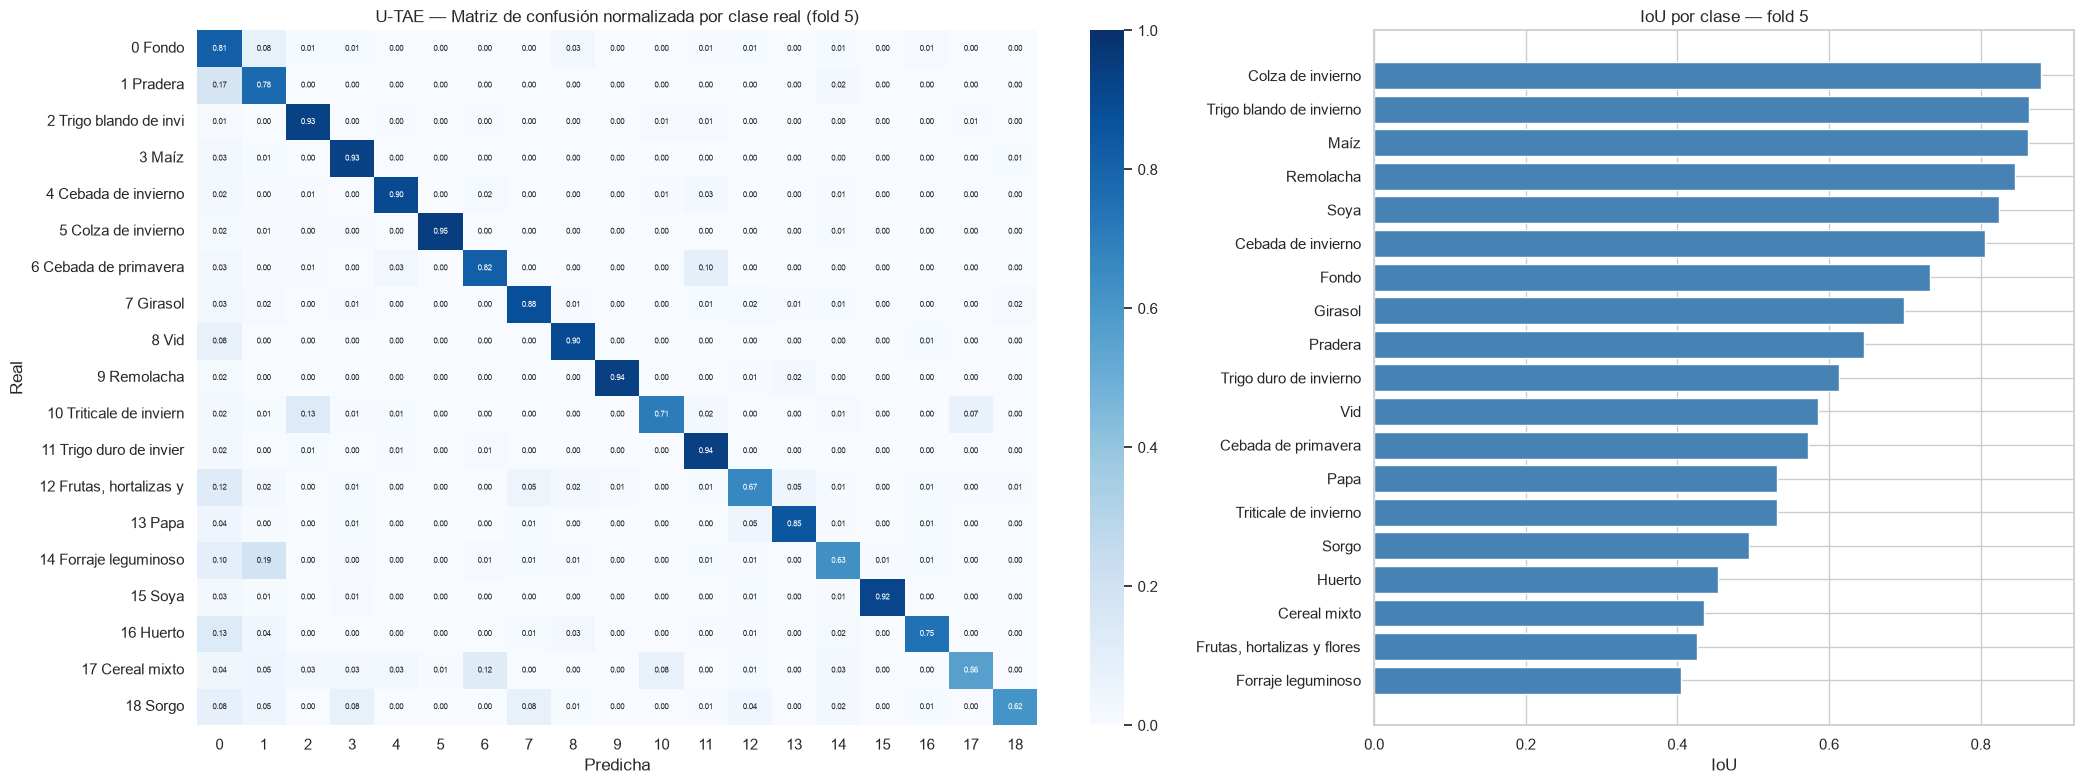

In [21]:
# ==============================================================================
# 7.3 MATRIZ DE CONFUSIÓN NORMALIZADA E IoU POR CLASE (FOLD 5)
# ==============================================================================
if EJECUTAR_PRUEBA:
    conf = res_test["conf"]; norm = conf / np.maximum(conf.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(21, 8), gridspec_kw={"width_ratios": [1.5, 1]})
    sns.heatmap(norm, ax=ax[0], cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 6},
                xticklabels=range(NUM_CLASSES), yticklabels=[f"{i} {NOMBRES_CLASES[i][:20]}" for i in range(NUM_CLASSES)])
    ax[0].set(title="U-TAE — Matriz de confusión normalizada por clase real (fold 5)", xlabel="Predicha", ylabel="Real")
    orden = np.argsort(res_test["iou"])
    ax[1].barh([NOMBRES_CLASES[i] for i in orden], res_test["iou"][orden], color="steelblue")
    ax[1].set(title="IoU por clase — fold 5", xlabel="IoU")
    plt.tight_layout(); plt.show()

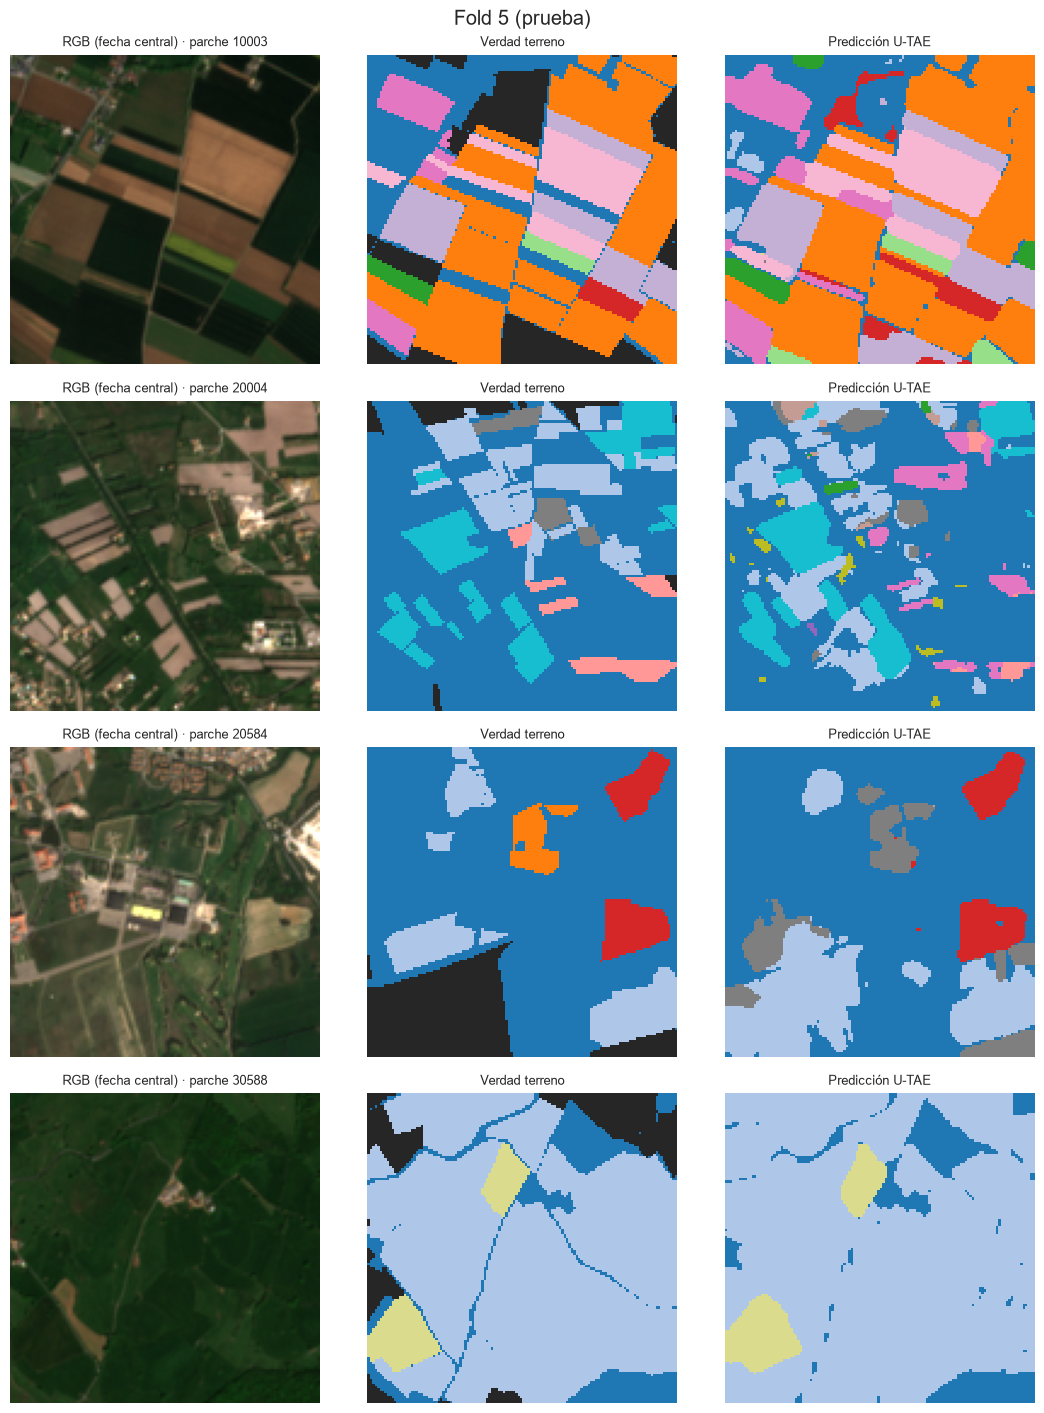

In [22]:
# ==============================================================================
# 7.4 EJEMPLOS CUALITATIVOS (RGB, VERDAD TERRENO Y PREDICCIÓN)
# ==============================================================================
from matplotlib.colors import ListedColormap
colores = plt.get_cmap("tab20")(np.linspace(0, 1, 20)); colores[19] = (0.15, 0.15, 0.15, 1)   # Void en gris
cmap = ListedColormap(colores)

ids_vis = IDS["test"] if EJECUTAR_PRUEBA else IDS["val"]
ids_demo = ids_vis[:: max(1, len(ids_vis) // 4)][:4]
fig, ax = plt.subplots(len(ids_demo), 3, figsize=(11, 3.6 * len(ids_demo)))
ax = np.atleast_2d(ax)
for fila, pid in enumerate(ids_demo):
    x, y, d = PastisDataset([pid], False, None, MEAN, STD)[0]
    with torch.no_grad():
        pred = predecir_logits(model, x[None].to(DEVICE), d[None].to(DEVICE), USAR_TTA).argmax(1)[0].cpu().numpy()
    bruto = np.load(ruta_s2(pid), mmap_mode="r")[len(DATES[pid]) // 2].astype(np.float32)   # fecha central
    rgb = np.clip(bruto[[2, 1, 0]].transpose(1, 2, 0) / 3000, 0, 1)                           # B4, B3, B2
    ax[fila, 0].imshow(rgb)
    ax[fila, 1].imshow(y.numpy(), cmap=cmap, vmin=0, vmax=19, interpolation="nearest")
    ax[fila, 2].imshow(pred, cmap=cmap, vmin=0, vmax=19, interpolation="nearest")
    for j, t in enumerate(["RGB (fecha central)", "Verdad terreno", "Predicción U-TAE"]):
        ax[fila, j].set_title(f"{t} · parche {pid}" if j == 0 else t, fontsize=9); ax[fila, j].axis("off")
plt.suptitle("Fold 5 (prueba)" if EJECUTAR_PRUEBA else "Fold 4 (validación)")
plt.tight_layout(); plt.show()

### 7.5 Interpretación de la Evaluación

- **Tabla 7.1 (parches completos):** es la evaluación propia de un modelo de segmentación y la que se reportaría en adelante. Incluye todos los píxeles válidos, también los bordes entre parcelas, que suelen ser los más difíciles.
- **Tabla 7.2 (muestra del Avance 5):** es la única comparación directa con los clasificadores por píxel, porque usa exactamente los mismos píxeles y etiquetas. Si la reconstrucción no coincide (mensaje de aviso), la comparación deja de ser exacta y debe tomarse como orientativa.
- **Matriz de confusión e IoU por clase:** permiten comprobar si las clases que en el Avance 5 quedaban cerca de 0 (Cebada de primavera, Triticale, Papa, Cereal mixto, Huerto, Sorgo) mejoran, y con qué clases se siguen confundiendo (típicamente entre cereales de invierno).

## 8. Conclusiones Metodológicas CRISP-ML(Q)

### Procedimiento
Se pasó de clasificadores por píxel con estadísticas temporales a un modelo de **segmentación espacio-temporal** que utiliza la secuencia completa de imágenes con sus fechas y el contexto espacial de cada parche. Se conservaron las particiones oficiales, la exclusión de Void y la definición de los macro promedios de los avances anteriores. La selección del checkpoint y del tipo de inferencia se hizo **solo con el fold 4**; el fold 5 se evaluó una única vez al final.

### Criterios de evaluación
El mIoU de validación guía la selección porque es la métrica estándar en segmentación semántica y, como Macro F1, da el mismo peso a cada clase. Se reportan también Macro F1 y Accuracy. Para no comparar conjuntos distintos, la comparación con el Avance 5 se hace sobre los mismos 9,000 píxeles de prueba.

### Limitaciones
- **Una sola corrida y una sola semilla:** no se estima la variabilidad entre entrenamientos.
- **Sin búsqueda sistemática de hiperparámetros:** se usó la configuración del artículo de U-TAE y valores razonables para la pérdida (pesos `1/√frecuencia` acotados, Dice con peso 1).
- **Solo Sentinel-2:** PASTIS también incluye Sentinel-1 (radar), que el artículo original aprovecha en variantes multimodales.
- **Submuestreo temporal en entrenamiento:** el modelo entrena con 32 fechas y se evalúa con la serie completa; la atención temporal admite longitudes variables, pero es una diferencia entre entrenamiento e inferencia.
- **Cómputo:** si `BATCH_SIZE` se redujo por la VRAM, la acumulación de gradientes mantiene el lote efectivo, pero las capas BatchNorm del decodificador ven lotes más pequeños.

### Posibles extensiones
Preentrenamiento autosupervisado (por ejemplo, tipo JEPA) sobre los parches sin usar etiquetas, muestreo que priorice parches con clases raras, fusión con Sentinel-1 y varias semillas para reportar intervalos.

La siguiente celda resume con números de esta misma ejecución.

In [23]:
# ==============================================================================
# 8.1 SÍNTESIS CUANTITATIVA DE ESTA EJECUCIÓN
# ==============================================================================
texto = f'''
**Síntesis de esta ejecución.** Entorno: {ENTORNO}; configuración `BATCH_SIZE={BATCH_SIZE}`, `T_TRAIN={T_TRAIN}`,
lote efectivo {BATCH_SIZE * ACCUM_STEPS}; {len(historial)} épocas registradas; mejor época {ck['epoca'] + 1}.
Inferencia elegida con validación: **{"TTA" if USAR_TTA else "una pasada"}**.

En **validación (fold 4, parches completos)** U-TAE obtuvo mIoU = **{res_val['mIoU']:.4f}**,
Macro F1 = **{res_val['Macro F1']:.4f}** y Accuracy = **{res_val['Accuracy']:.4f}**.
'''
if EJECUTAR_PRUEBA:
    fila_utae = comparacion_av5.iloc[-1]
    casi_cero = [NOMBRES_CLASES[i] for i in range(NUM_CLASSES) if res_test["f1"][i] < 0.05]
    texto += f'''
En **prueba (fold 5, parches completos)**: mIoU = **{res_test['mIoU']:.4f}**, Macro F1 = **{res_test['Macro F1']:.4f}**,
Accuracy = **{res_test['Accuracy']:.4f}**.

Sobre **los mismos 9,000 píxeles del Avance 5**: U-TAE Macro F1 = **{fila_utae['Macro F1']:.4f}**
frente a 0.3447 del Voting heterogéneo y 0.3275 del LDA (diferencia con Voting: **{fila_utae['Macro F1'] - 0.3447:+.4f}**).

Clases con F1 < 0.05 en prueba: {", ".join(casi_cero) if casi_cero else "ninguna"}.
'''
else:
    texto += "\nEl fold 5 todavía no se ha evaluado (entrenamiento en pausa o `EVALUAR_PRUEBA=False`).\n"
if MODO_RAPIDO:
    texto += "\n**Atención:** ejecución en MODO_RAPIDO (prueba de humo); estas cifras no son resultados del modelo.\n"
display(Markdown(texto))


**Síntesis de esta ejecución.** Entorno: Local; configuración `BATCH_SIZE=2`, `T_TRAIN=32`,
lote efectivo 4; 100 épocas registradas; mejor época 99.
Inferencia elegida con validación: **TTA**.

En **validación (fold 4, parches completos)** U-TAE obtuvo mIoU = **0.6507**,
Macro F1 = **0.7756** y Accuracy = **0.8323**.

En **prueba (fold 5, parches completos)**: mIoU = **0.6424**, Macro F1 = **0.7703**,
Accuracy = **0.8290**.

Sobre **los mismos 9,000 píxeles del Avance 5**: U-TAE Macro F1 = **0.7606**
frente a 0.3447 del Voting heterogéneo y 0.3275 del LDA (diferencia con Voting: **+0.4159**).

Clases con F1 < 0.05 en prueba: ninguna.


### Referencias

- Garnot, V. S. F., & Landrieu, L. (2021). *Panoptic Segmentation of Satellite Image Time Series with Convolutional Temporal Attention Networks*. ICCV. Código: https://github.com/VSainteuf/utae-paps (licencia MIT).
- Assran, M., et al. (2023). *Self-Supervised Learning from Images with a Joint-Embedding Predictive Architecture*. CVPR.

## Declaración sobre el uso de herramientas de inteligencia artificial

**Equipo:** 13  
**Integrantes:**
- José Eduardo De Moraes López - A01634782
- André Zaragoza Bonilla - A01797076
- David Alejandro Velázquez Valdéz - A01632648

**Actividad:** Avance 6. Segmentación espacio-temporal con U-TAE

**Herramientas de IA utilizadas:** Claude (Anthropic, Claude Code, 2026).

**Uso declarado:**
- Revisión crítica de un borrador previo del notebook y corrección de errores de acceso a datos, reanudación y uso de memoria.
- Integración en el notebook de la implementación oficial de U-TAE (repositorio `VSainteuf/utae-paps`, licencia MIT), con una modificación de eficiencia documentada en la sección 3.
- Apoyo en la implementación del ajuste automático de memoria, del bucle de entrenamiento con checkpoints y de la comparación con el Avance 5 sobre los mismos píxeles.
- Apoyo en la redacción de las explicaciones metodológicas.

**Verificación y responsabilidad del equipo:**
- Las decisiones de diseño (particiones, tratamiento de Void, pérdida, métrica de selección y métricas reportadas) fueron definidas por el equipo y se mantienen desde los avances anteriores.
- La ejecución con los datos reales, la revisión de los resultados y las conclusiones son responsabilidad académica de los integrantes del equipo.

**Contribución individual del equipo:**
- **José Eduardo De Moraes López:** Validación de las particiones oficiales de PASTIS (folds 1–5) y metadatos, cálculo de estadísticas de normalización por banda, definición de los pesos de clase y estructuración del pipeline de datos (`PastisDataset`).
- **André Zaragoza Bonilla:** Integración y optimización de la arquitectura U-TAE (`smart_forward`), implementación de la función de pérdida combinada (cross-entropy ponderada + Dice) y verificación del cálculo de métricas (`mIoU`, `Macro F1` y `Accuracy`).
- **David Alejandro Velázquez Valdéz:** Implementación del ajuste automático de memoria en GPU (`bfloat16` y acumulación de gradientes), ejecución del entrenamiento con checkpoints, evaluación en validación/prueba (fold 5) y comparación con el Avance 5.

**Decisiones principales:**
- **Cambio de enfoque:** se pasó de clasificadores por píxel a U-TAE porque los primeros no aprovechan la secuencia temporal completa ni el contexto espacial. Se descartó JEPA como paso principal por tratarse de preentrenamiento autosupervisado que no resuelve el desbalance; queda como posible extensión.
- **Pérdida:** cross-entropy ponderada (`1/√frecuencia`, acotada) + Dice. Se descartó el inverso puro de la frecuencia por inestable con un desbalance de 342:1.
- **Selección:** mejor checkpoint por mIoU de validación; el fold 5 se reservó para la evaluación final.